# Disney World Wait Times 2018
Student name: Aljoharh mohammed Alnjm

## Project Idea
This project explores Disney World ride wait times in 2018. I chose this dataset because it includes different rides, hours, and ticket seasons that can be compared.

Research questions:
- Which rides have the highest average wait times?
- How do wait times change by hour and day of the week?
- Do wait times differ between ticket seasons?
- What is the difference between posted and actual wait times?

Source: https://github.com/LucyMcGowan/touringplans

Column descriptions: https://lucymcgowan.github.io/touringplans/reference/touringplans_2018.html

Each row contains hourly data for a ride on a park operating day. It does not represent one visitor.

## 1. Loading the Data
The original file is in R format, so I first convert it to CSV.

In [1]:
%matplotlib inline
import importlib.util
if importlib.util.find_spec("pyreadr") is None:
    %pip install -q pyreadr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyreadr
import urllib.request
from pathlib import Path

url = "https://raw.githubusercontent.com/LucyMcGowan/touringplans/main/data/touringplans_2018.rda"
if not Path("touringplans_2018.rda").exists():
    urllib.request.urlretrieve(url, "touringplans_2018.rda")
result = pyreadr.read_r("touringplans_2018.rda")
df = result["touringplans_2018"]
df.to_csv("touringplans_2018.csv", index=False)
df.head()
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Exploring the Data

In [2]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (66492, 17)
<class 'pandas.DataFrame'>
RangeIndex: 66492 entries, 0 to 66491
Data columns (total 17 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   park_date                            66492 non-null  object 
 1   wait_hour                            66492 non-null  int32  
 2   attraction_name                      66492 non-null  str    
 3   wait_minutes_actual_avg              9698 non-null   float64
 4   wait_minutes_posted_avg              66438 non-null  float64
 5   attraction_wait_per_hundred_average  66492 non-null  float64
 6   attraction_duration                  66492 non-null  float64
 7   attraction_park                      66492 non-null  str    
 8   attraction_land                      66492 non-null  str    
 9   park_open                            66492 non-null  float64
 10  park_close                           66492 non-null  float64
 11  park_extr

In [3]:
df.describe()

,wait_hour,wait_minutes_actual_avg,wait_minutes_posted_avg,attraction_wait_per_hundred_average,attraction_duration,park_open,park_close,park_extra_magic_morning,park_extra_magic_evening,park_temperature_average,park_temperature_high
count,66492.000000,9698.000000,66438.000000,66492.000000,66492.000000,66492.000000,66492.000000,66492.000000,66492.000000,66492.000000,66492.000000
mean,14.385084,37.794428,53.829052,3.910613,7.730020,31623.335138,76647.157553,0.308233,0.068880,73.961641,82.397061
std,4.432905,462.016033,40.563702,1.608636,5.857308,1488.038531,4722.256167,0.461767,0.253253,9.462063,8.817043
min,0.000000,0.000000,0.000000,1.500000,1.500000,25200.000000,59400.000000,0.000000,0.000000,39.750000,51.110000
25%,11.000000,13.500000,23.125000,3.000000,3.500000,32400.000000,72000.000000,0.000000,0.000000,69.850000,78.290000
50%,14.000000,26.000000,45.000000,4.000000,6.000000,32400.000000,75600.000000,0.000000,0.000000,76.370000,84.660000
75%,18.000000,42.000000,74.545455,4.500000,8.000000,32400.000000,81000.000000,1.000000,0.000000,81.660000,89.180000
max,23.000000,45231.500000,306.818182,10.000000,20.000000,32400.000000,90000.000000,1.000000,1.000000,85.180000,93.350000


In [4]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:
park_date                                  0
wait_hour                                  0
attraction_name                            0
wait_minutes_actual_avg                56794
wait_minutes_posted_avg                   54
attraction_wait_per_hundred_average        0
attraction_duration                        0
attraction_park                            0
attraction_land                            0
park_open                                  0
park_close                                 0
park_extra_magic_morning                   0
park_extra_magic_evening                   0
park_ticket_season                         0
park_temperature_average                   0
park_temperature_high                      0
attraction_short_name                      0
dtype: int64
Duplicate rows: 0


## 3. Cleaning the Data
I use a copy of the data, remove exact duplicate rows if any, and shorten some column names.

Many actual wait times are missing, so I do not fill them with the mean. Most charts use posted wait times. The comparison uses only rows where both wait times are available.

Negative wait times or values above a full day (1,440 minutes) are treated as invalid. The original file is kept. Other high values are not automatically removed.

In [5]:
clean = df.copy()
clean = clean.drop_duplicates()
clean = clean.rename(columns={
    "park_date": "Date",
    "wait_hour": "Hour",
    "attraction_name": "Ride",
    "attraction_park": "Park",
    "wait_minutes_posted_avg": "PostedWait",
    "wait_minutes_actual_avg": "ActualWait",
    "park_ticket_season": "Season"
})

clean["Date"] = pd.to_datetime(clean["Date"])
for col in ["PostedWait", "ActualWait"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")
    invalid = (clean[col] < 0) | (clean[col] > 1440)
    print(col, "Invalid values:", invalid.sum())
    clean.loc[invalid, col] = float("nan")

clean["Day"] = clean["Date"].dt.day_name()
clean["Month"] = clean["Date"].dt.month
clean["WaitDifference"] = clean["PostedWait"] - clean["ActualWait"]
clean.to_csv("clean_data.csv", index=False)
clean.head()

PostedWait

 Invalid values: 0
ActualWait Invalid values: 2


,Date,Hour,Ride,ActualWait,PostedWait,attraction_wait_per_hundred_average,attraction_duration,Park,attraction_land,park_open,park_close,park_extra_magic_morning,park_extra_magic_evening,Season,park_temperature_average,park_temperature_high,attraction_short_name,Day,Month,WaitDifference
0,2018-06-30,7,Alien Swirling Saucers,NaN,150.000000,10.0,2.5,Disney's Hollywood Studios,Toy Story Land,28800.0,82800.0,0.0,0.0,peak,79.44,85.29,Alien Saucers,Saturday,6,NaN
1,2018-06-30,8,Alien Swirling Saucers,NaN,127.083333,10.0,2.5,Disney's Hollywood Studios,Toy Story Land,28800.0,82800.0,0.0,0.0,peak,79.44,85.29,Alien Saucers,Saturday,6,NaN
2,2018-06-30,9,Alien Swirling Saucers,NaN,91.111111,10.0,2.5,Disney's Hollywood Studios,Toy Story Land,28800.0,82800.0,0.0,0.0,peak,79.44,85.29,Alien Saucers,Saturday,6,NaN
3,2018-06-30,10,Alien Swirling Saucers,NaN,136.000000,10.0,2.5,Disney's Hollywood Studios,Toy Story Land,28800.0,82800.0,0.0,0.0,peak,79.44,85.29,Alien Saucers,Saturday,6,NaN
4,2018-06-30,11,Alien Swirling Saucers,NaN,173.333333,10.0,2.5,Disney's Hollywood Studios,Toy Story Land,28800.0,82800.0,0.0,0.0,peak,79.44,85.29,Alien Saucers,Saturday,6,NaN


In [6]:
print(clean[["PostedWait", "ActualWait"]].isnull().sum())
print("Number of rides:", clean["Ride"].nunique())
print("First date:", clean["Date"].min())
print("Last date:", clean["Date"].max())
missing_pct = clean["ActualWait"].isnull().mean() * 100
print(f"{missing_pct:.1f}% of actual wait times are missing")

PostedWait       54
ActualWait    56796
dtype: int64
Number of rides: 14
First date: 2018-01-01 00:00:00
Last date: 2018-12-31 00:00:00
85.4% of actual wait times are missing


## 4. Analysis and Charts
### Chart 1: Distribution of Posted Wait Times
This chart shows the most common wait times in the data.

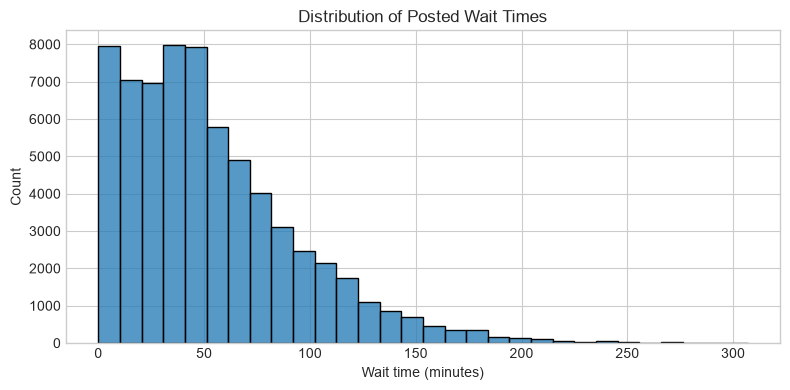

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(data=clean, x="PostedWait", bins=30)
plt.title("Distribution of Posted Wait Times")
plt.xlabel("Wait time (minutes)")
plt.tight_layout()
plt.show()

### Chart 2: Number of Records per Ride
This chart shows differences in data coverage between rides.

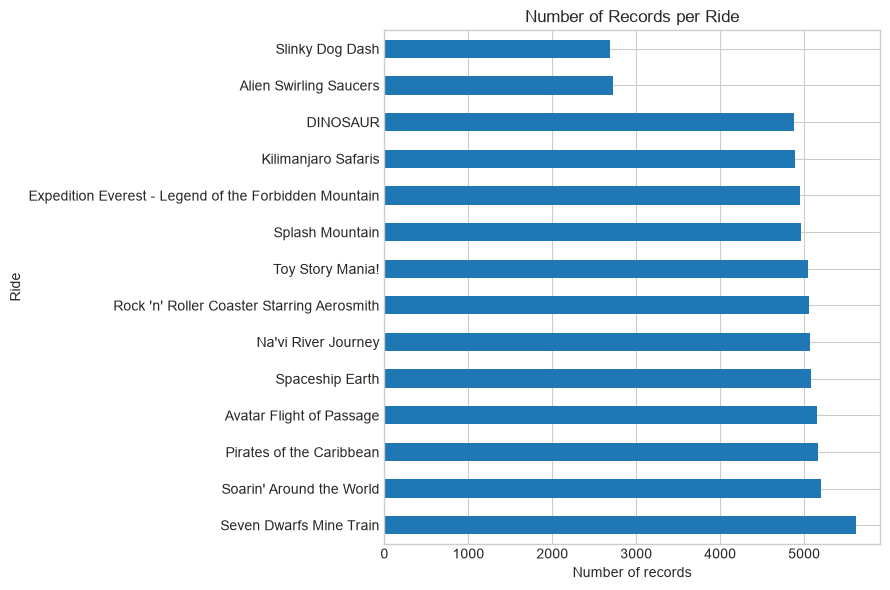

In [8]:
plt.figure(figsize=(9, 6))
clean["Ride"].value_counts().plot(kind="barh")
plt.title("Number of Records per Ride")
plt.xlabel("Number of records")
plt.tight_layout()
plt.show()

### Chart 3: Average Wait by Ride
This comparison uses the average of available records. It is not weighted by visitor counts.

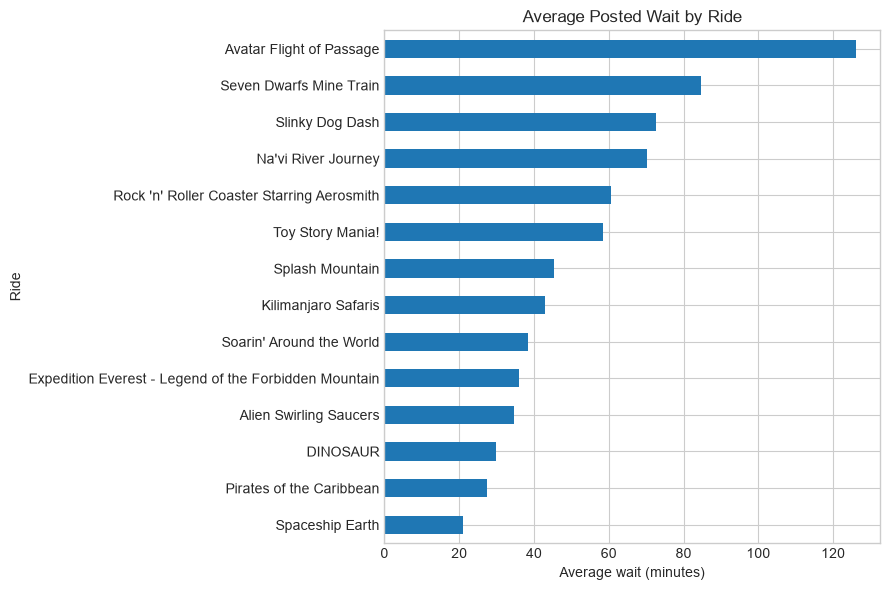

In [9]:
ride_average = clean.groupby("Ride")["PostedWait"].mean().sort_values()
plt.figure(figsize=(9, 6))
ride_average.plot(kind="barh")
plt.title("Average Posted Wait by Ride")
plt.xlabel("Average wait (minutes)")
plt.tight_layout()
plt.show()

### Chart 4: Wait Times by Hour
This chart shows how the average changes during the day. Available rides may differ between hours. Hour 0 means midnight.
The peak hour refers to the highest observed mean in this dataset, not a general rule for visiting Disney World. The boxplot and record counts help explain differences between hours.

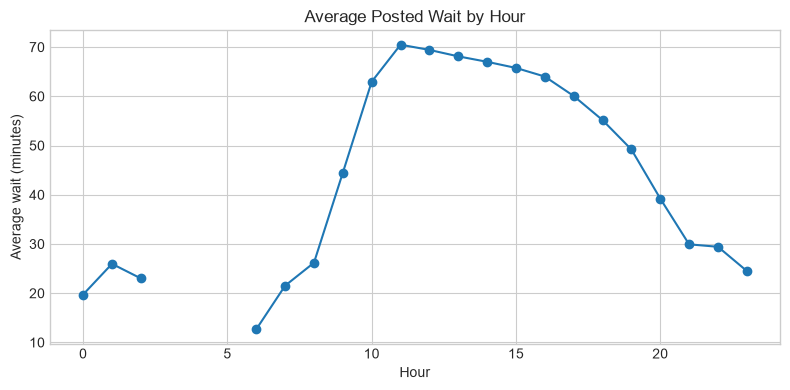

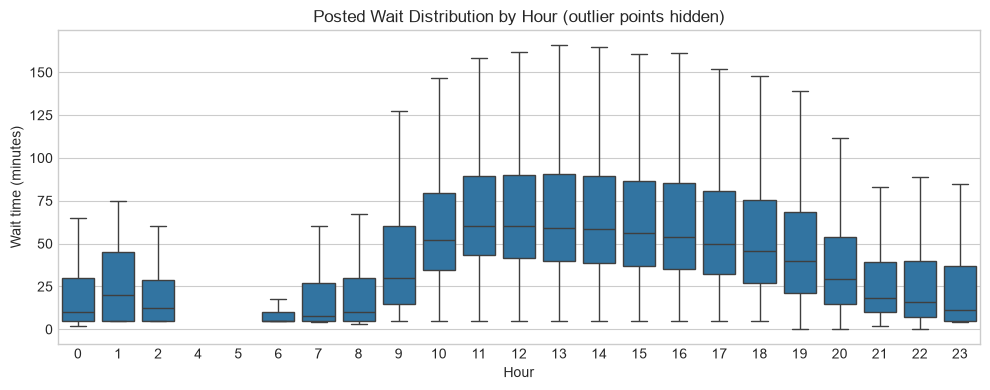

,count,mean,median
Hour,,,
0,428,19.7,10.0
1,51,26.0,20.0
2,10,23.0,12.5
4,0,NaN,NaN
5,0,NaN,NaN
6,318,12.7,5.0
7,1519,21.5,7.5
8,3814,26.2,10.0
9,4572,44.5,30.0


In [10]:
hour_average = clean.groupby("Hour")["PostedWait"].mean()
plt.figure(figsize=(8, 4))
hour_average.plot(kind="line", marker="o")
plt.title("Average Posted Wait by Hour")
plt.xlabel("Hour")
plt.ylabel("Average wait (minutes)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(data=clean, x="Hour", y="PostedWait", showfliers=False)
plt.title("Posted Wait Distribution by Hour (outlier points hidden)")
plt.ylabel("Wait time (minutes)")
plt.tight_layout()
plt.show()
display(clean.groupby("Hour")["PostedWait"].agg(["count", "mean", "median"]).round(1))

### Chart 5: Wait Times by Day of the Week
These are descriptive averages. A small difference between Saturday and Sunday does not establish a meaningful difference. Repeated observations from the same rides and dates are related, so a standard ANOVA on all hourly rows would assume more independence than the data provides. A formal comparison would need to account for ride, date, season, and time of day.

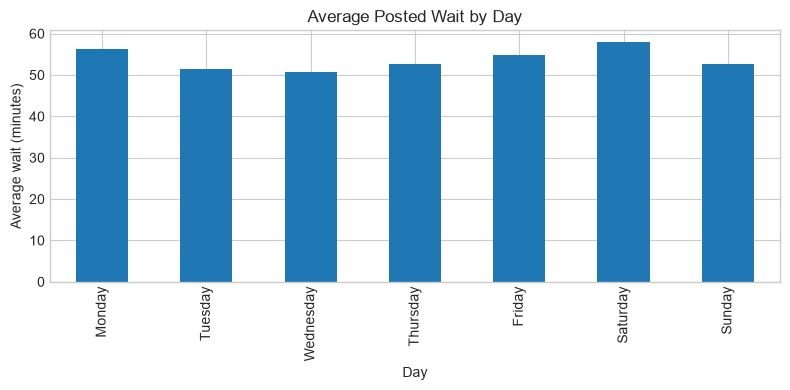

In [11]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_average = clean.groupby("Day")["PostedWait"].mean().reindex(days)
plt.figure(figsize=(8, 4))
day_average.plot(kind="bar")
plt.title("Average Posted Wait by Day")
plt.ylabel("Average wait (minutes)")
plt.tight_layout()
plt.show()

### Chart 6: Comparing Ticket Seasons
The boxplot shows the distribution of wait times in each season. Outlier points are hidden in the chart only to make it easier to read.

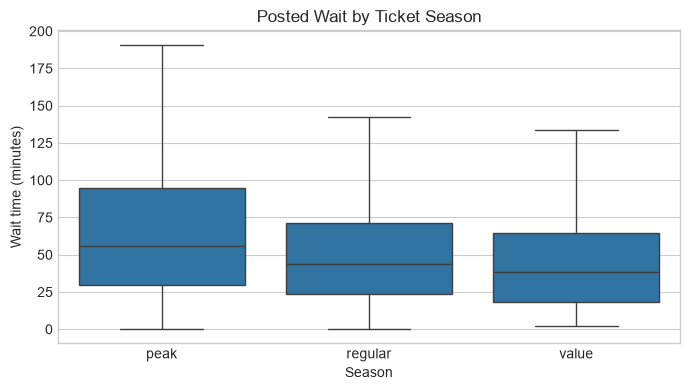

In [12]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=clean, x="Season", y="PostedWait", showfliers=False)
plt.title("Posted Wait by Ticket Season")
plt.ylabel("Wait time (minutes)")
plt.tight_layout()
plt.show()

### Chart 7: Posted vs Actual Wait Times
Only rows with both values are used. The red line represents equal wait times.

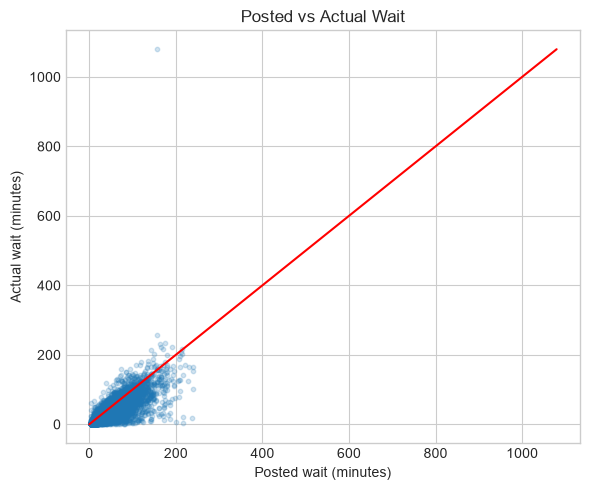

Rows used in the comparison: 9642
Average difference: 12.42 minutes
Wait difference summary (posted minus actual):


count    9642.00
mean       12.42
std        21.73
min      -922.85
25%         2.59
50%         9.50
75%        19.00
max       218.00
Name: WaitDifference, dtype: float64

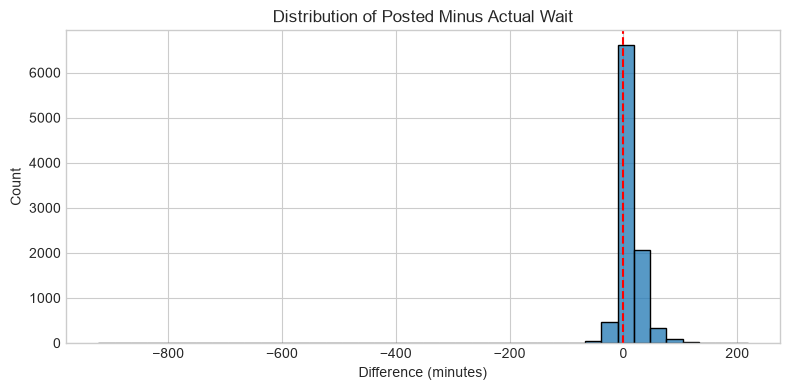

In [13]:
comparison = clean.dropna(subset=["PostedWait", "ActualWait"])
plt.figure(figsize=(6, 5))
plt.scatter(comparison["PostedWait"], comparison["ActualWait"], alpha=0.2, s=10)
limit = comparison[["PostedWait", "ActualWait"]].max().max()
plt.plot([0, limit], [0, limit], color="red")
plt.title("Posted vs Actual Wait")
plt.xlabel("Posted wait (minutes)")
plt.ylabel("Actual wait (minutes)")
plt.tight_layout()
plt.show()
print("Rows used in the comparison:", len(comparison))
print("Average difference:", round(comparison["WaitDifference"].mean(), 2), "minutes")
print("Wait difference summary (posted minus actual):")
display(comparison["WaitDifference"].describe().round(2))
plt.figure(figsize=(8, 4))
sns.histplot(comparison["WaitDifference"], bins=40)
plt.axvline(0, color="red", linestyle="--")
plt.title("Distribution of Posted Minus Actual Wait")
plt.xlabel("Difference (minutes)")
plt.tight_layout()
plt.show()
assert clean.loc[clean["ActualWait"].isna(), "WaitDifference"].isna().all()

### Chart 8: Ride and Hour Heatmap
Each cell shows the mean posted wait for a ride and hour. Blank cells indicate no available values.

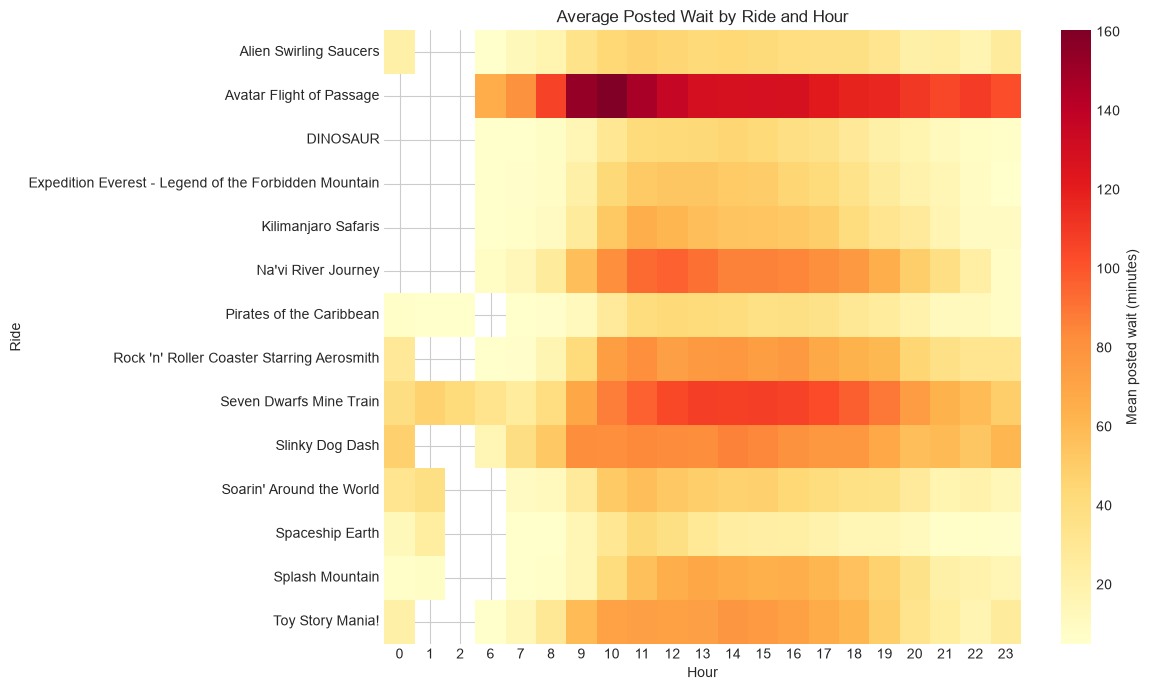

In [14]:
pivot = clean.pivot_table(values="PostedWait", index="Ride", columns="Hour", aggfunc="mean")
plt.figure(figsize=(12, 7))
sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": "Mean posted wait (minutes)"})
plt.title("Average Posted Wait by Ride and Hour")
plt.tight_layout()
plt.show()

### Top 5 Rides by Average Posted Wait

In [15]:
top5 = clean.groupby("Ride")["PostedWait"].agg(["count", "mean", "median"])
top5 = top5.sort_values("mean", ascending=False).head(5).round(1)
display(top5)

,count,mean,median
Ride,,,
Avatar Flight of Passage,5144,126.2,120.0
Seven Dwarfs Mine Train,5620,84.5,81.7
Slinky Dog Dash,2687,72.6,69.4
Na'vi River Journey,5070,70.2,72.2
Rock 'n' Roller Coaster Starring Aerosmith,5061,60.6,56.7


## 5. Results Summary

In [16]:
summary = pd.DataFrame({
    "Metric": ["Highest mean ride", "Lowest mean ride", "Peak observed hour", "Peak observed day", "Actual wait missing", "Paired records", "Mean posted minus actual", "Median posted minus actual"],
    "Value": [ride_average.idxmax(), ride_average.idxmin(), hour_average.idxmax(), day_average.idxmax(), f"{missing_pct:.1f}%", len(comparison), f"{comparison['WaitDifference'].mean():.1f} minutes", f"{comparison['WaitDifference'].median():.1f} minutes"]
})
display(summary)
print("Average posted wait by season:")
display(clean.groupby("Season")["PostedWait"].agg(["count", "mean", "median"]).round(1))

,Metric,Value
0,Highest mean ride,Avatar Flight of Passage
1,Lowest mean ride,Spaceship Earth
2,Peak observed hour,11
3,Peak observed day,Saturday
4,Actual wait missing,85.4%
5,Paired records,9642
6,Mean posted minus actual,12.4 minutes
7,Median posted minus actual,9.5 minutes


Average posted wait by season:


,count,mean,median
Season,,,
peak,15514,65.8,56.1
regular,36765,51.3,43.9
value,14159,47.2,38.3


- Avatar Flight of Passage has the highest average posted wait time, at about 126 minutes.
- Spaceship Earth has the lowest average posted wait time, at about 21 minutes.
- In rows with both values available, posted wait times are about 12.4 minutes higher than actual wait times on average.
- The missing percentage is calculated above from the cleaned data. The limited coverage means that the posted-versus-actual comparison cannot be generalized to all records.
- Two actual wait values exceeded a full day and were replaced with missing values in the cleaned data.

## 6. Conclusion and Limitations
This project covers loading, cleaning, grouping, and comparing data using Pandas, Matplotlib, and Seaborn.

The data covers selected rides in 2018 and does not describe current conditions. Data coverage differs between rides and hours. The number of visitors behind each average is unknown. These relationships do not prove that ticket season or visit time directly causes the differences.

Future analysis could use newer data and examine each ride separately. The cleaned data could also be used in a Streamlit dashboard with ride, park, season, and date filters.

## 7. Downloading the CSV from Colab
Run the next cell to download the cleaned data.

In [17]:
try:
    from google.colab import files
    files.download("clean_data.csv")
except ImportError:
    print("File saved as clean_data.csv")

File saved as clean_data.csv
